# Arbeitspaket (AP) 2: Advanced Data Preparation & Exploratory Data Analysis (EDA)

## Python Libraries und Settings

In [52]:
# Libraries
import os
import re
import random
import sqlite3
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from datetime import datetime, timedelta
from sqlalchemy import create_engine, text

# seaborn graphics settings
sns.set_theme(color_codes=True)

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Show current working directory
print(os.getcwd())

/workspaces/python_exploratory_data_analysis/00_LNW_Wdh


#### <b>Aufgabe (1): Lesen Sie den Datensatz 'smartphone_data.csv' aus dem Order 'Data' ein, und speichern Sie diesen in einem pandas DataFrame.</b>
<b>Details zur Aufgabenstellung:</b>
- Zeigen Sie die Dimension des DataFrames (Zeilen und Spalten) im Jupyter Notebook an.
- Zeigen Sie die Datentypen sämtlicher Spalten des DataFrames im Jupyter Notebook an.
- Zeigen Sie die ersten Zeilen des DataFrames im Jupyter Notebook an.<br><br>

- Tipp: Berücksichtigen Sie den Pfad der Ablage der Daten im Ordner Data ('./Data/smartphone_data.csv').

<b style="color: gray;">(max. erreichbare Punkte: 4)</b>

In [53]:
# Einlesen der Daten 'smartphone_data.csv' aus dem Order 'Data' in ein DataFrame 'df'
df = pd.read_csv("./Data/smartphone_data.csv", sep=";")

# Anzeigen der Dimension des DataFrames (Zeilen und Spalten)
print("Shape: ", df.shape)

# Anzeigen der Datentypen sämtlicher Spalten des DataFrames
print("Columns: ", df.dtypes)

# Anzeigen der ersten 5 Zeilen des DataFrames
print("First lines: \n")
df.head(5)

Shape:  (5000, 12)
Columns:  offer_id                   int64
dealer_plz                 int64
dealer_city               object
dealer_street_house_nr    object
make                      object
model                     object
price_raw                 object
camera_resolution_raw     object
battery_life_raw          object
storage_size_raw          object
screen_size_raw           object
description_raw           object
dtype: object
First lines: 



,offer_id,dealer_plz,dealer_city,dealer_street_house_nr,make,model,price_raw,camera_resolution_raw,battery_life_raw,storage_size_raw,screen_size_raw,description_raw
0,83197857,6394,Volketswil,Blaserstrasse 19,Apple,iPhone 13,CHF 2518.-,20 MP,16 hrs,256 GB,6.1 IN,"Langlebige Batterie mit Schnellladefunktion, d..."
1,36687537,9532,Oberwil,Furrerstrasse 1,Vivo,Vivo V21,CHF 266.-,12 MP,16 hrs,128 GB,5.8 IN,Modernste Gesichtserkennungstechnologie für Si...
2,66722344,2227,Rüti,Maierstrasse 31,Vivo,Vivo V21,CHF 424.-,12 MP,20 hrs,256 GB,5.8 IN,Ultra-HD-Display für eine atemberaubende Bildq...
3,56164955,5766,Bülach,Sidlerstrasse 6,Google,Pixel 6a,CHF 597.-,12 MP,25 hrs,64 GB,5.8 IN,Mit Stiftunterstützung für Kreativität und Prä...
4,94374605,8304,Belp,Steinerstrasse 8,Google,Pixel 6,CHF 1934.-,20 MP,23 hrs,64 GB,5.8 IN,Aufgeteilt in benutzerfreundliche Kategorien f...


#### <b>Aufgabe (2): Extrahieren Sie die numerischen Werte der folgenden Variablen, und speichern Sie diese in separaten Variablen im DataFrame ab.</b>
<b>Details zur Aufgabenstellung:</b>
- Extrahieren Sie die numerischen Werte der folgenden Variablen, und speichern Sie diese in separaten Variablen ab:
  - price_raw
  - camera_resolution_raw
  - battery_life_raw
  - storage_size_raw
  - screen_size_raw<br>
- Benennen Sie die Spalten der neuen Variablen als (in Klammern ist der Datentyp angegeben):
  - price (int64)
  - camera_resolution (int64)
  - battery_life (int64)
  - storage_size (int64)
  - screen_size (float64)
- Stellen Sie ein Subset des DataFrames nur mit den neuen Spalten und den ersten 5 Zeilen im Jupyter Notebook dar.<br><br>
- Die folgenden regular expressions sind eine Hilfestellung zum Lösen der Aufgabe:<br>
  ```python
  "CHF\s*(\d+)\.-"
  "(\d+)\s*MP"
  "(\d+)\s*hrs"
  "(\d+)\s*GB"
  "(\d+\.\d+)\s*IN"
  ```
  
<b style="color: gray;">(max. erreichbare Punkte: 8)</b>

In [54]:
# Extrahieren der numerischen Werte aus 'price_raw' und speichern in separaten Variablen
price = []
for i in df['price_raw']:
    d1 = re.findall("CHF\s*(\d+)\.-", i)
    try:
        d2 = d1[0].strip()
    except:
        d2 = None
    price.append(d2)

df['price'] = pd.Series(price, dtype="Int64")

In [55]:
# Extrahieren der numerischen Werte aus 'camera_resolution_raw' und speichern in separaten Variablen
camera_resolution = []
for i in df['camera_resolution_raw']:
    d1 = re.findall("(\d+)\s*MP", i)
    try:
        d2 = d1[0].strip()
    except:
        d2 = None
    camera_resolution.append(d2)

df['camera_resolution'] = pd.Series(camera_resolution, dtype="Int64")

In [56]:
# Extrahieren der numerischen Werte aus 'battery_life_raw' und speichern in separaten Variablen
battery_life = []
for i in df['battery_life_raw']:
    d1 = re.findall("(\d+)\s*hrs", i)
    try:
        d2 = d1[0].strip()
    except:
        d2 = None
    battery_life.append(d2)

df['battery_life'] = pd.Series(battery_life, dtype="Int64")

In [57]:
# Extrahieren der numerischen Werte aus 'storage_size_raw' und speichern in separaten Variablen
storage_size = []
for i in df['storage_size_raw']:
    d1 = re.findall("(\d+)\s*GB", i)
    try:
        d2 = d1[0].strip()
    except:
        d2 = None
    storage_size.append(d2)

df['storage_size'] = pd.Series(storage_size, dtype="Int64")

In [58]:
# Extrahieren der numerischen Werte aus 'screen_size_raw' und speichern in separaten Variablen (Tipp: float64 statt int64)
screen_size = []
for i in df['screen_size_raw']:
    d1 = re.findall("(\d+\.\d+)\s*IN", i)
    try:
        d2 = d1[0].strip()
    except:
        d2 = None
    screen_size.append(d2)

df['screen_size'] = pd.Series(screen_size, dtype="Float64")

In [59]:
# Anzeigen Subset des DataFrames nur mit den neuen Variablen und den ersten 5 Zeilen
df[['price','camera_resolution','battery_life','storage_size','screen_size']].head(5)

,price,camera_resolution,battery_life,storage_size,screen_size
0,2518,20,16,256,6.1
1,266,12,16,128,5.8
2,424,12,20,256,5.8
3,597,12,25,64,5.8
4,1934,20,23,64,5.8


#### <b>Aufgabe (3): Erstellen Sie statistische Kennzahlen zu den numerischen Variablen im DataFrame.</b>
<b>Details zur Aufgabenstellung:</b>
- Berechnen Sie die statistische Kennzahlen für die Variablen 'price', 'camera_resolution', 'battery_life', 'storage_size', 'screen_size'.
- Die statistische Kennzahlen, welche berechnet werden sollen sind (engl. Bezeichnungen): 
  - Count
  - Mean
  - Standard Deviation (std)
  - Minimum
  - 25th Percentile (= 1st Quartile)
  - 50th Percentile (= Median)
  - 75th Percentile (= 3rd Quartile)
  - Maximum
  - Skewness
- Stellen Sie die berechneten statistische Kennzahlen im Jupyter Notebook dar (es können auch verschiedene Ergebnistabellen angezeigt werden).<br><br>

- Tipp: Nicht alle Python - Methoden verwenden automatisch nur die numerischen Variablen. In diesen Fällen muss ein Subset der numerischen Variablen erstellt werden.

<b style="color: gray;">(max. erreichbare Punkte: 4)</b>

In [79]:
# Einlesen der aufbereiteten Daten (damit alle auf dem gleichen Stand sind)
engine = create_engine('sqlite:///./Data/smartphone_data_prepared.db')
df = pd.read_sql_query("""SELECT * FROM smartphone_data_prepared""", con=engine)
engine.dispose()

# Berechnung der statistischen Kennzahlen der numerischen Spalten in 'df'
df_subset = df[['price','camera_resolution','battery_life','storage_size','screen_size']]
print('Statistics:\n', round(df_subset.describe(),2))

# Separate Berechnung der Skewness der numerischen Spalten
print('---\nSkewness:\n', df_subset.skew())

Statistics:
           price  camera_resolution  battery_life  storage_size  screen_size
count   5000.00            5000.00       5000.00       5000.00      5000.00
mean    1391.03              22.99         22.56        211.00         6.15
std     1359.78              21.90          5.31        165.66         0.36
min       18.00              12.00         15.00         64.00         5.80
25%      546.00              12.00         18.00         64.00         5.80
50%      975.50              16.00         22.00        128.00         6.10
75%     1763.00              20.00         26.00        256.00         6.50
max    17091.00             108.00         35.00        512.00         6.90
---
Skewness:
 price                3.005238
camera_resolution    2.757996
battery_life         0.485760
storage_size         0.965733
screen_size          0.661643
dtype: float64


#### <b>Aufgabe (4): Erstellen Sie eine Pivot-Tabelle mit den Mittwelwerten der numerischen Variablen pro Hersteller.</b>
<b>Details zur Aufgabenstellung:</b>
- Die Angabe zum Hersteller finden Sie in der Variable 'make'.
- Verwenden Sie die für die Mittelwertsberechnung die Variablen 'price', 'camera_resolution', 'battery_life', 'storage_size', 'screen_size'.
- Stellen Sie die Pivot-Tabelle im Jupyter Notebook dar.

<b style="color: gray;">(max. erreichbare Punkte: 4)</b>

In [81]:
# Erstellen der Pivot-Tabelle
pivot_table = pd.pivot_table(df[['make','price','camera_resolution','battery_life','storage_size','screen_size']],
                             index=['make'],
                             values={'price': np.mean, 
                                     'camera_resolution': np.mean,
                                     'battery_life': np.mean, 
                                     'storage_size': np.mean, 
                                     'screen_size': np.mean}).round(2)

#Anzeigen der Pivot-Tabelle
pivot_table

,battery_life,camera_resolution,price,screen_size,storage_size
make,,,,,
Apple,22.61,23.23,2120.24,6.13,208.90
Google,22.48,22.32,1583.31,6.16,214.17
Samsung,22.62,22.37,1343.23,6.16,209.06
Vivo,22.65,23.80,842.75,6.15,214.25
Xiaomi,22.41,23.26,1058.12,6.13,208.87


#### <b>Aufgabe (5): Erstellen Sie ein Histogramm der Variable 'price'.</b>
<b>Details zur Aufgabenstellung: </b>
- Setzen Sie die Anzahl der Klassen (engl.: bins) auf den Wert 25.
- Beschriften Sie die Achsen des Histogramms, und fügen Sie einen Titel hinzu.
- Fügen Sie der Graphik ein Gitternetz (engl.: grid) hinzu.
- Zeigen Sie das Histogramm im Jupyter Notebook an. 

<b style="color: gray;">(max. erreichbare Punkte: 8)</b>

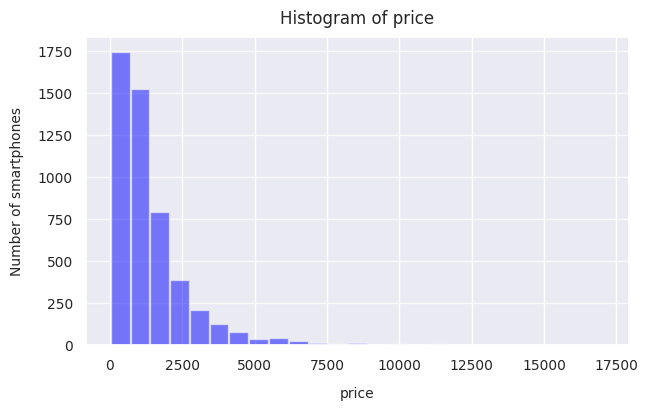

In [96]:
# Erstellen, Beschriften und Anzeigen des Histogramms
fig = plt.figure( figsize=(7,4))
plt.xticks(fontsize=14, rotation=0)
plt.yticks(fontsize=14, rotation=0)
n, bins, patches = plt.hist(x=df['price'], 
                            bins=25, 
                            color='blue',
                            alpha=0.5, 
                            rwidth=0.95
                   )
plt.grid(True)
plt.ticklabel_format(style='plain')
plt.grid(axis='y', alpha=0.75)

# Set labels
plt.xlabel('price', fontsize=10, labelpad=10)
plt.ylabel('Number of smartphones', fontsize=10, labelpad=10)
plt.title('Histogram of price', fontsize=12, pad=10)

# Set fontsize of tick labels
plt.xticks(fontsize = 10)
plt.yticks(fontsize = 10)

plt.show()

#### <b>Aufgabe (6): Erstellen Sie einen gruppierten Boxplot mit den Preisen pro Hersteller.</b>
<b>Details zur Aufgabenstellung: </b>
- Verwenden Sie die Python Library seaborn für die Erstellung des gruppieren Boxplots.
- Die Angabe zum Hersteller (=Gruppierungsvariable) finden Sie in der Variable 'make'.
- Beschriften Sie die Achsen und geben Sie der Graphik einen Titel.
- Stellen Sie den gruppierten Boxplot im Jupyter Notebook dar.<br><br>

- Tipp: Für die Erstellung des gruppierten Boxplots können Sie Vorlagen aus der seaborn - Hilfe verwenden (vgl. Abschnitt: 'Group by a categorical variable ...'):<br><br>
  https://seaborn.pydata.org/generated/seaborn.boxplot.html


<b style="color: gray;">(max. erreichbare Punkte: 8)</b>

<Axes: title={'center': 'Prices per make'}, xlabel='price', ylabel='make'>

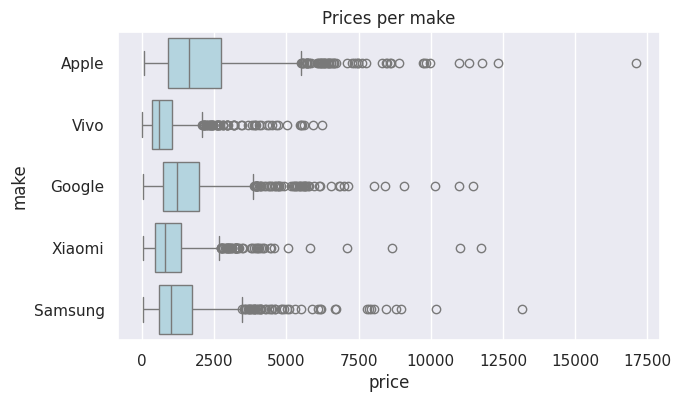

In [97]:
# Erstellen, Beschriften und Anzeigen des gruppierten Boxplots
plt.figure(figsize=(7,4))
plt.ticklabel_format(style='plain')
plt.title('Prices per make')
sns.boxplot(x=df['price'], y=df['make'],color="lightblue")

#### <b>Aufgabe (7): Erstellen Sie ein Barchart mit der Anzahl Smartphones pro Hersteller.</b>
<b>Details zur Aufgabenstellung:</b>
- Ergänzen Sie den Python Code unten dort wo notwendig.
- Die Angabe zum Hersteller finden Sie in der Variable 'make'.
- Im Barchart müssen die Hersteller auf der vertikalen und die Anzahl Smartphones auf der horizontalen Achse abgebildet sein.
- Im Barchart müssen die Anzahl Smartphones pro Hersteller der Grösse nach absteigend sortiert sein.
- Beschriften Sie die Achsen des Barcharts und geben Sie dem Barchart einen Titel.<br><br>

<b style="color: gray;">(max. erreichbare Punkte: 8)</b>

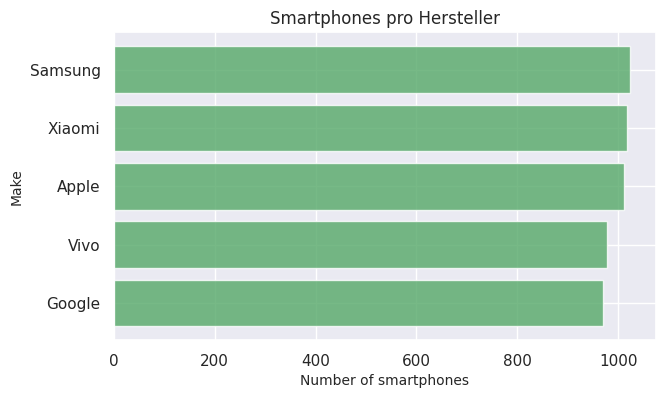

In [91]:
# Gruppierung der Daten nach 'make' und Berechnung der Anzahl Smartphones
df_bar = df['make'].value_counts().sort_values(ascending=True)

# Zusammenstellen der Werte für den Barchart
napart = list(df_bar.values)
index = list(df_bar.index.values)
y_pos = np.arange(len(index))

# Erstellen des Barcharts
fig, ax = plt.subplots(figsize=(7,4))
ax.barh(y_pos, napart, align='center', color='g', alpha=0.8)
ax.set_yticks(y_pos, index)
ax.set_xlabel('Number of smartphones', fontsize=10)
ax.set_ylabel('Make', fontsize=10)
ax.set_title('Smartphones pro Hersteller')

# Anzeigen der Graphik
plt.show()

#### <b>Aufgabe (8): Erstellen Sie eine Correlation-Heatmap auf der Basis der numerischen Variablen.</b>
<b>Details zur Aufgabenstellung:</b>
- Verwenden Sie die Variablen 'price', 'camera_resolution', 'battery_life', 'storage_size', 'screen_size'.
- Berechnen Sie auf zwei Nachkommastellen gerundete Korrelationskoeffizienten als Basis für die Correlation-Matrix und -Heatmap.
- Stellen Sie die Correlation-Matrix im Jupyter Notebook dar.
- Stellen Sie die Correlation-Heatmap im Jupyter Notebook dar.

<b style="color: gray;">(max. erreichbare Punkte: 8)</b>

<function matplotlib.pyplot.show(close=None, block=None)>

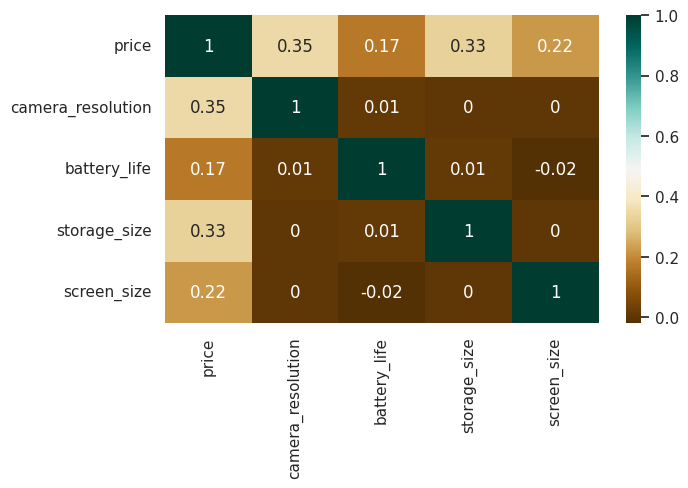

In [93]:
# Erstellen Correlation-Matrix numerischen Variablen
corr = df[['price', 
            'camera_resolution',
            'battery_life',
            'storage_size',
            'screen_size',  
            ]].corr().round(2)

# Erstellen der Heatmap aus Correlation-Matrix
plt.figure(figsize=(7,4))
sns.heatmap(corr, 
            cmap="BrBG", 
            annot=True)

# Anzeigen der Graphik
plt.show

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [94]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('IP Address:', socket.gethostbyname(socket.gethostname()))
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1030-azure
Datetime: 2025-11-04 12:01:11
Python Version: 3.11.14
IP Address: 127.0.0.1
-----------------------------------
